# RoadSafe Chicago | Partie 04 : Analyse exploratoire univariée

**Projet** : étude de l'accidentologie routière à Chicago (Open Data, API Socrata)
**Données** : 112 056 accidents enregistrés en 2024 (`data/processed/crashes_2024.parquet`)
**Problématique** : *Comment évoluent la fréquence et la gravité des accidents routiers à Chicago, et quels facteurs sont associés à leur gravité ?*

---

### Objectif
Décrire chaque variable clé, une par une, pour comprendre **quand**, **dans quelles conditions** et **avec quelle gravité** surviennent les accidents, avant d'étudier les liens entre variables.

### Sommaire
1. Accidents par mois
2. Accidents par jour de la semaine
3. Accidents par heure
4. Rythme de la semaine (jour × heure)
5. Conditions : météo, luminosité, chaussée
6. Types de collision et causes déclarées
7. Gravité des accidents

### Précautions de lecture
- Les volumes sont **normalisés par jour** quand les périodes comparées n'ont pas la même durée.
- Un grand nombre d'accidents reflète d'abord **l'exposition** (le volume de circulation), pas un risque plus élevé.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

df = pd.read_parquet("../data/processed/crashes_2024.parquet")
print(df.shape)

(112056, 61)


In [2]:
df.head()

,crash_record_id,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,...,delay_valid,injury_info_available,is_injury,is_fatal,is_severe,is_weekend,time_slot,season,is_dark,speed_class
0,5082d6e9f9c5c96660e7ec7fd416549e50d3130af3fc5c...,2024-06-27 13:45:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Journée (10-15h),Été,False,≤20
1,fd34aa4f12f00106b32134531fc6e805590dbe89fef502...,2024-06-22 18:07:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,NOT DIVIDED,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Soir (16-19h),Été,False,25-30
2,f0a652bf48a8c08c8a26cc981e39ed757cd41f8a771761...,2024-06-23 08:41:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,REAR TO REAR,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Matin (6-9h),Été,False,≤20
3,973cda531480f4006c44691e5cc8931b9fd9d719a21264...,2024-06-19 07:35:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,TURNING,T-INTERSECTION,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Matin (6-9h),Été,False,25-30
4,e66fd58b2afc22ec6aa176f149d17467d49f7ae1c83910...,2024-07-07 20:47:00,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PARKED MOTOR VEHICLE,OTHER,STRAIGHT AND LEVEL,...,True,True,True,False,False,True,Nuit (20-23h),Été,True,25-30


## 1. Accidents par mois

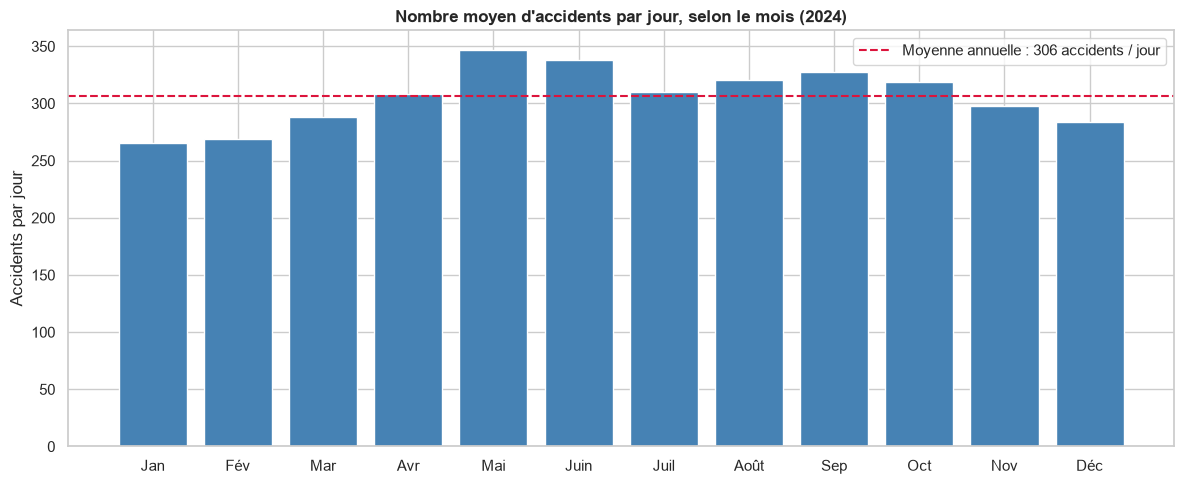

In [3]:
# Accident par mois 

mois_labels = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
jours_par_mois = pd.Series(pd.date_range("2024-01-01", "2024-12-31").month).value_counts().sort_index()

par_mois = df["crash_month"].value_counts().sort_index()
par_jour_moyen = par_mois / jours_par_mois.values

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(mois_labels, par_jour_moyen.values, color="steelblue")
ax.axhline(par_jour_moyen.mean(), color="crimson", linestyle="--",
           label=f"Moyenne annuelle : {par_jour_moyen.mean():.0f} accidents / jour")
ax.set_title("Nombre moyen d'accidents par jour, selon le mois (2024)", fontweight="bold")
ax.set_ylabel("Accidents par jour"); ax.legend()
save_fig("04_1_accidents_par_mois")

**Analyse.** Une fois chaque mois ramené à son nombre de jours, la moyenne est de **306 accidents par jour**. Janvier et février sont les mois les plus calmes (266 et 269 accidents par jour), mai et juin les plus chargés (347 et 338). Contrairement à l'intuition, ce n'est pas l'hiver qui concentre les accidents à Chicago mais la fin du printemps et l'été : le froid et la neige réduisent probablement les déplacements, en particulier les déplacements de loisirs, plus qu'ils ne multiplient les accidents.

## 2. Accidents par jour de la semaine

In [4]:
jours_labels = {1: "Dimanche", 2: "Lundi", 3: "Mardi", 4: "Mercredi", 5: "Jeudi", 6: "Vendredi", 7: "Samedi"}
ordre = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]

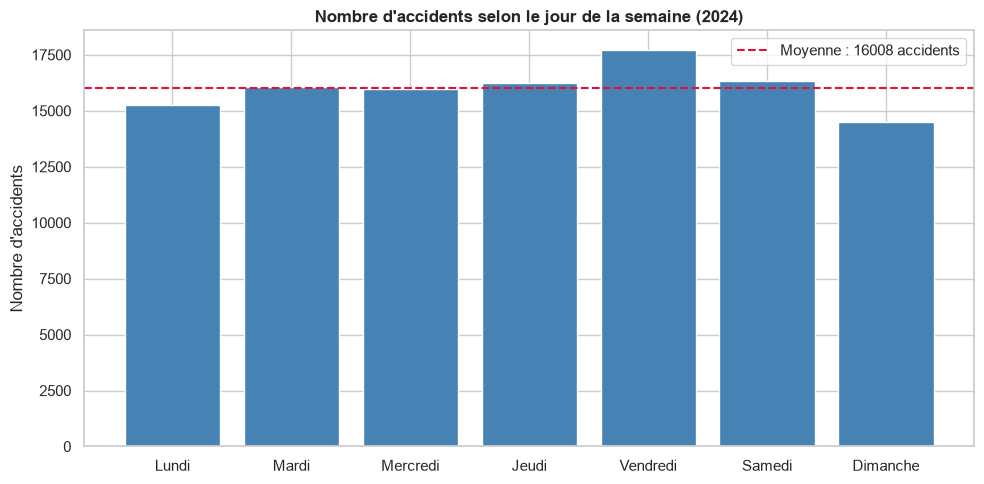

In [5]:
# Accidents par jour de la semaine

par_jour = df["crash_day_of_week"].map(jours_labels).value_counts().reindex(ordre)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(par_jour.index, par_jour.values, color="steelblue")
ax.axhline(par_jour.mean(), color="crimson", linestyle="--",
           label=f"Moyenne : {par_jour.mean():.0f} accidents")
ax.set_title("Nombre d'accidents selon le jour de la semaine (2024)", fontweight="bold")
ax.set_ylabel("Nombre d'accidents"); ax.legend()
save_fig("04_2_accidents_par_jour")

**Analyse.** Le vendredi est le jour le plus accidentogène (17 702 accidents) et le dimanche le plus calme (14 489), soit un écart d'environ 20 %. Les autres jours sont très proches. À noter : 2024 compte 53 lundis et 53 mardis contre 52 pour les autres jours, ce qui gonfle très légèrement ces deux jours.

## 3. Accidents par heure

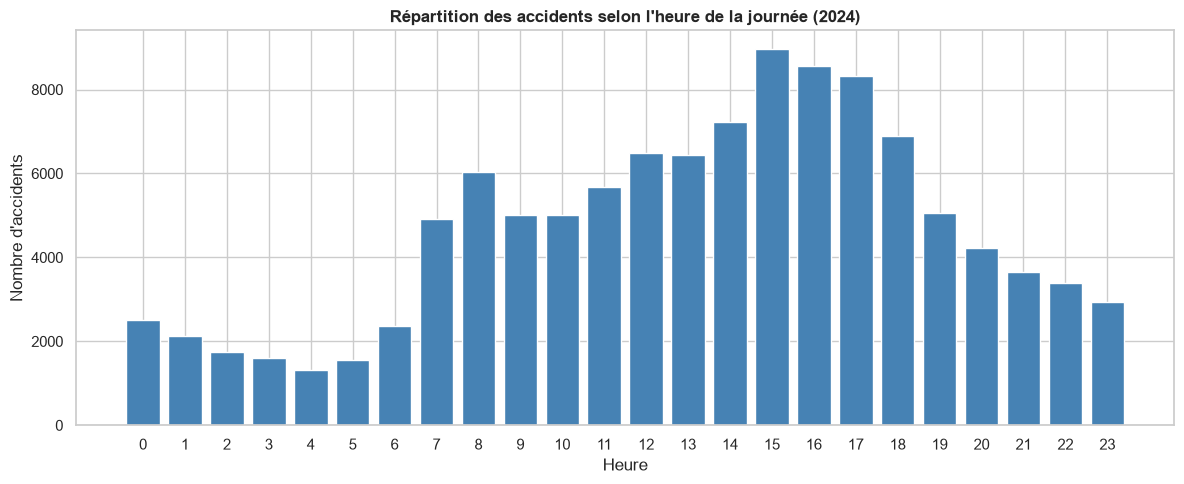

In [6]:
# Accident par heure 

par_heure = df["crash_hour"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(par_heure.index, par_heure.values, color="steelblue")
ax.set_xticks(range(24))
ax.set_title("Répartition des accidents selon l'heure de la journée (2024)", fontweight="bold")
ax.set_xlabel("Heure"); ax.set_ylabel("Nombre d'accidents")
save_fig("04_3_accidents_par_heure")

**Analyse.** Le profil suit le rythme des déplacements : un minimum vers 4 h (1 321 accidents sur l'année), une montée rapide à l'heure de pointe du matin (pic à 8 h), puis un plateau qui culmine entre 15 h et 17 h (près de 9 000 accidents à 15 h). La pointe du soir est nettement plus forte que celle du matin, car elle cumule retours du travail, sorties d'école et déplacements de loisirs.

## 4. Rythme de la semaine (jour x heure)

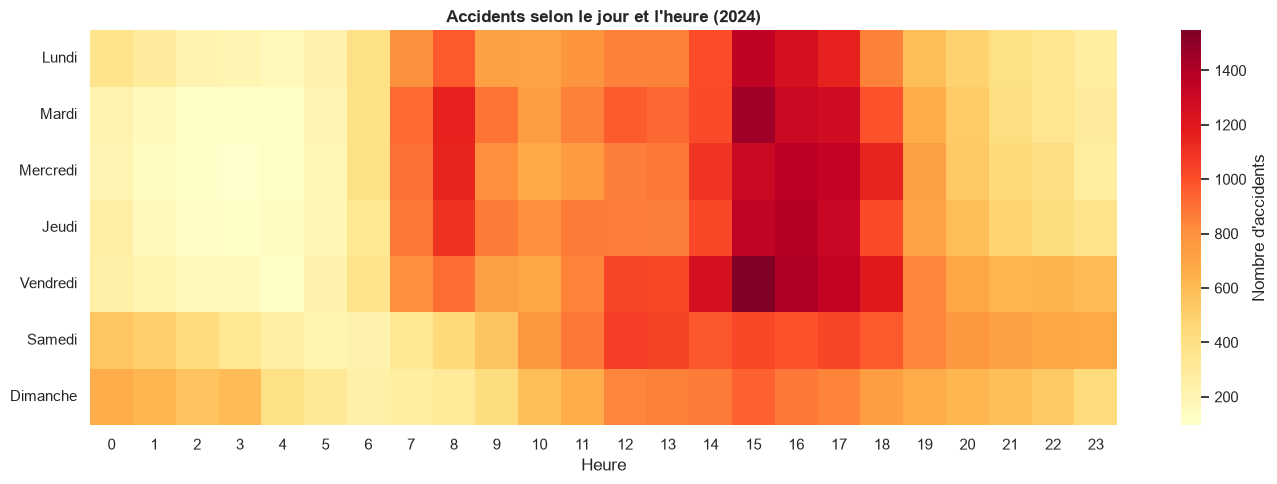

In [7]:
# Heatmap accidents par jour et heure

heatmap = (df.assign(jour=df["crash_day_of_week"].map(jours_labels))
             .pivot_table(index="jour", columns="crash_hour", values="crash_record_id", aggfunc="count")
             .reindex(ordre))


fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(heatmap, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Nombre d'accidents"})
ax.set_title("Accidents selon le jour et l'heure (2024)", fontweight="bold")
ax.set_xlabel("Heure"); ax.set_ylabel("")
save_fig("04_4_heatmap_jour_heure")

**Analyse.** Les jours ouvrés partagent le même profil, avec un maximum le vendredi à 15 h (1 547 accidents). Le week-end se distingue nettement : peu d'accidents le matin (environ 330 à 7 h le samedi contre 800 à 900 en semaine), mais un volume nocturne bien supérieur. Le samedi et le dimanche entre 0 h et 3 h, on compte 2 à 5 fois plus d'accidents qu'en semaine aux mêmes heures : ce sont les nuits du vendredi et du samedi soir.

## 5. Conditions : météo, luminosité, chaussée

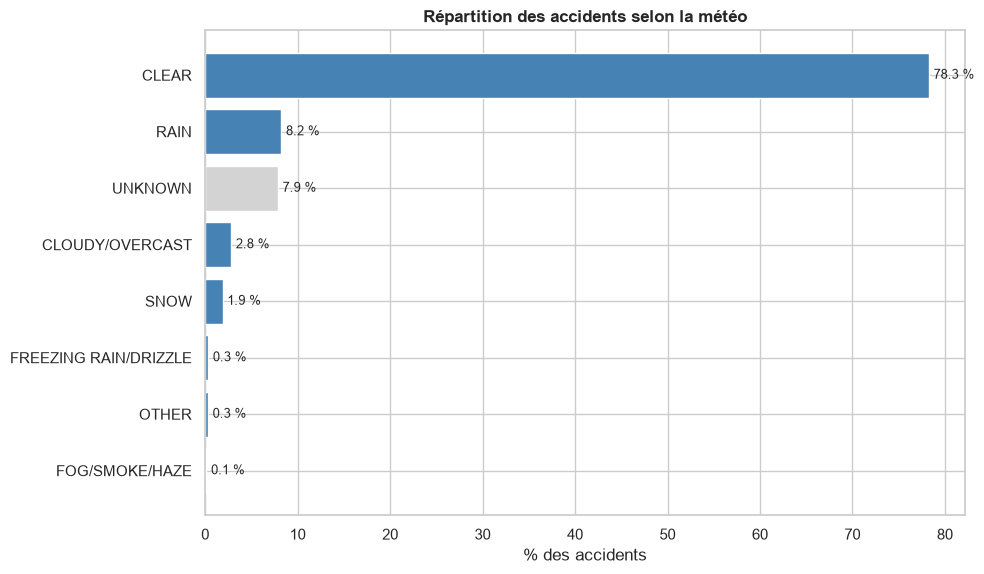

In [8]:
# repartition des accidents selon la météo

def plot_repartition(col, titre, nom_fichier, top=8):
    parts = df[col].value_counts(normalize=True).mul(100).head(top).sort_values()
    colors = ["lightgray" if v == "UNKNOWN" else "steelblue" for v in parts.index]
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(parts) + 1.5))
    ax.barh(parts.index.astype(str), parts.values, color=colors)
    for i, v in enumerate(parts.values):
        ax.text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=9)
    ax.set_title(titre, fontweight="bold"); ax.set_xlabel("% des accidents")
    save_fig(nom_fichier)

plot_repartition("weather_condition", "Répartition des accidents selon la météo", "04_5a_meteo")

**Analyse.** 78 % des accidents surviennent par temps clair et 8 % sous la pluie. Ces parts reflètent d'abord la fréquence de chaque météo dans l'année : on ne peut pas en conclure que le temps clair est plus dangereux. Le rôle de la météo sur la gravité est étudié en taux dans les parties 05 à 07.

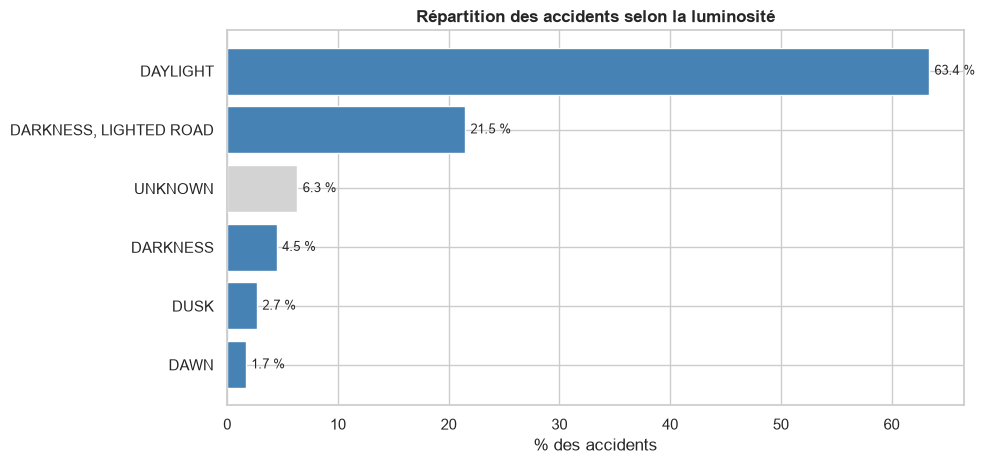

In [9]:
# Répartition des accidents selon la luminosité
plot_repartition("lighting_condition", "Répartition des accidents selon la luminosité", "04_5b_luminosite")

**Analyse.** 63 % des accidents ont lieu de jour et 26 % de nuit. La très grande majorité des accidents nocturnes se produit sur voie éclairée (21,5 % contre 4,5 % sans éclairage), ce qui reflète un réseau urbain largement équipé en éclairage public. Les accidents de nuit sur voie non éclairée forment donc un petit groupe, dont les taux seront plus incertains.

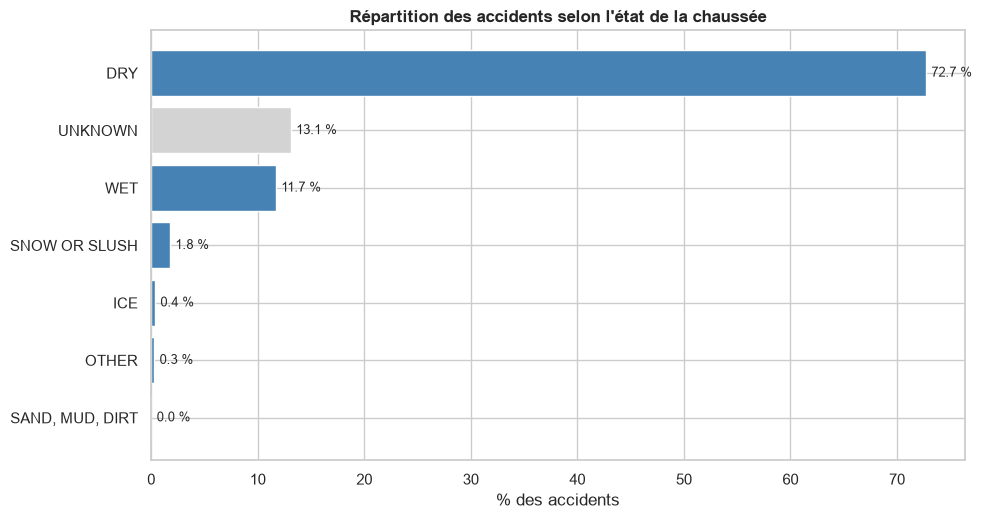

In [10]:
# Répartition des accidents selon l'état de la chaussée
plot_repartition("roadway_surface_cond", "Répartition des accidents selon l'état de la chaussée", "04_5c_chaussee")

**Analyse.** 73 % des accidents se produisent sur chaussée sèche et 12 % sur chaussée mouillée. Neige et glace restent marginales (2,2 % à elles deux), malgré l'hiver rigoureux de Chicago. C'est aussi la variable de contexte qui compte le plus d'inconnues (13 %).

## 6. Types de collision et causes déclarées

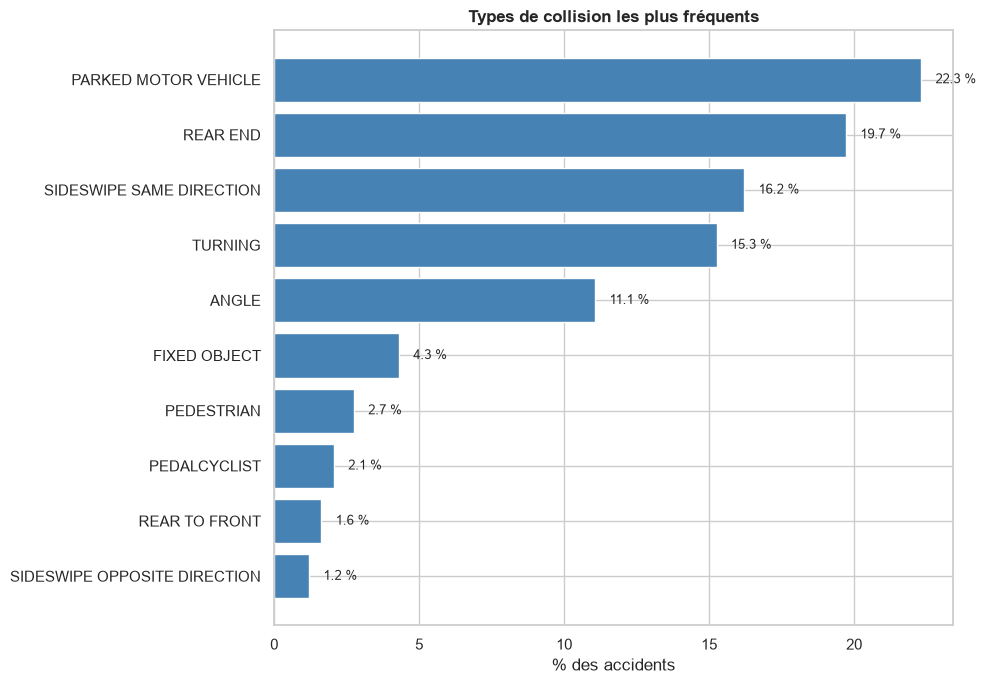

In [11]:
# Types de collision les plus fréquents

plot_repartition("first_crash_type", "Types de collision les plus fréquents", "04_6a_types_collision", top=10)

**Analyse.** Les trois types les plus fréquents sont des accrochages entre véhicules : contre un véhicule stationné (22 %), par l'arrière (20 %) et latéral dans le même sens (16 %). Les collisions avec piétons (2,7 %) et avec cyclistes (2,1 %) sont rares en volume. La partie 05 montre pourtant que ce sont, de loin, les plus graves.

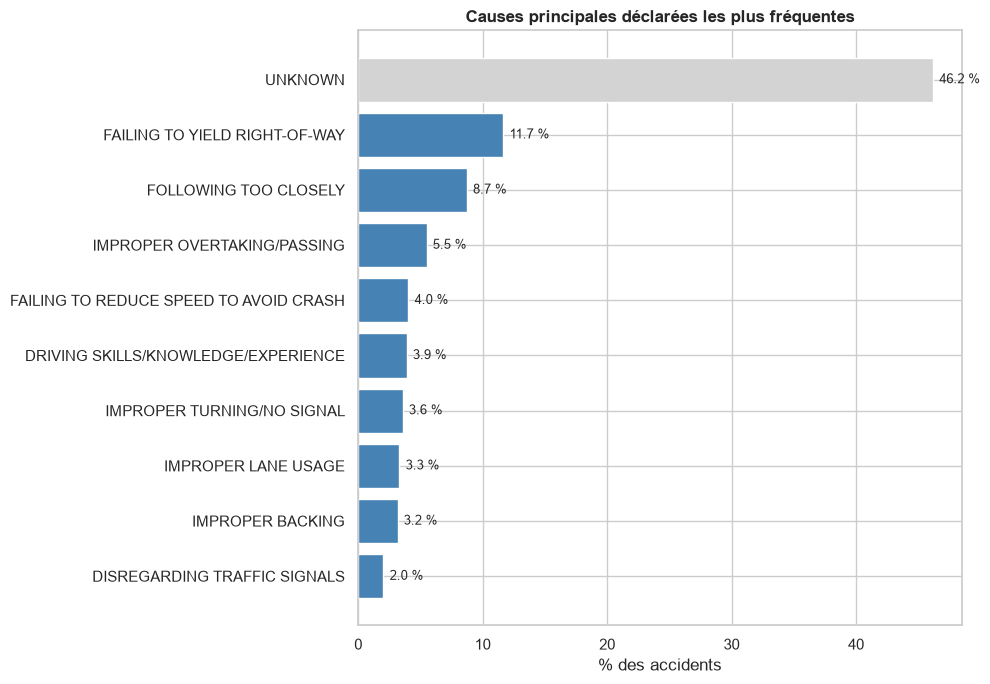

In [12]:
# Causes principales déclarées par la police
plot_repartition("prim_contributory_cause", "Causes principales déclarées les plus fréquentes", "04_6b_causes", top=10)

**Analyse.** Près de la moitié des causes principales sont inconnues (46 %), ce qui limite fortement cette variable. Parmi les causes renseignées, les plus fréquentes relèvent du comportement du conducteur : refus de priorité (11,7 %), distance de sécurité insuffisante (8,7 %), dépassement ou changement de voie irrégulier (5,5 %). Ces causes sont saisies par la police sur le terrain et ne sont pas intégrées au modèle de la partie 07.

## 7. Gravité des accidents

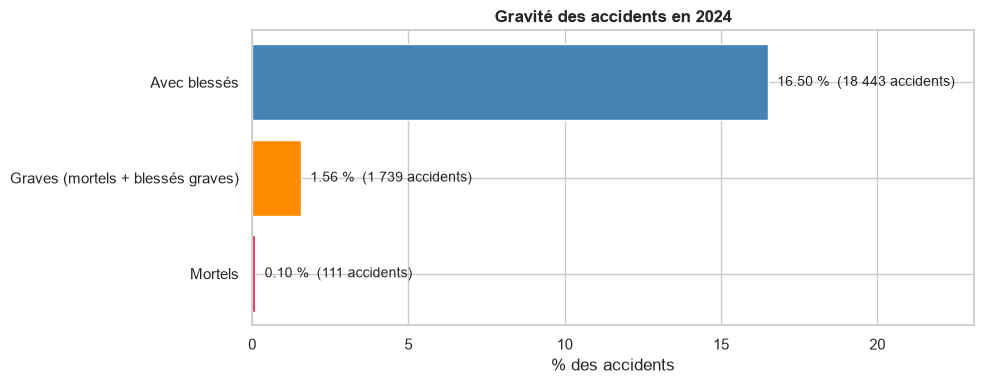

In [13]:
# Gravité 

gravite = pd.Series({
    "Avec blessés": df["is_injury"].mean() * 100,
    "Graves (mortels + blessés graves)": df["is_severe"].mean() * 100,
    "Mortels": df["is_fatal"].mean() * 100,
})
effectifs = pd.Series({
    "Avec blessés": df["is_injury"].sum(),
    "Graves (mortels + blessés graves)": df["is_severe"].sum(),
    "Mortels": df["is_fatal"].sum(),
})

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(gravite.index[::-1], gravite.values[::-1], color=["crimson", "darkorange", "steelblue"])
for i, (v, n) in enumerate(zip(gravite.values[::-1], effectifs.values[::-1])):
    ax.text(v + 0.3, i, f"{v:.2f} %  ({n:,} accidents)".replace(",", " "), va="center", fontsize=10)
ax.set_xlim(0, gravite.max() * 1.4)
ax.set_title("Gravité des accidents en 2024", fontweight="bold"); ax.set_xlabel("% des accidents")
save_fig("04_7_gravite")

**Analyse.** 16,5 % des accidents font au moins un blessé (18 443), 1,56 % sont graves (1 739) et 0,10 % sont mortels (111). La très grande majorité des accidents n'a donc que des conséquences matérielles. Cette rareté justifie d'utiliser `is_severe` plutôt que `is_fatal` pour comparer les contextes dans la suite de l'étude.

## Bilan

- **Quand ?** Les accidents suivent le rythme de la circulation : plus nombreux de mai à octobre, en fin d'après midi et le vendredi, plus rares l'hiver et la nuit. Le week-end se distingue par un volume nocturne élevé.
- **Dans quelles conditions ?** La majorité des accidents a lieu de jour, par temps clair, sur chaussée sèche, ce qui correspond simplement aux conditions les plus fréquentes.
- **Quoi ?** Les accrochages entre véhicules dominent en volume ; piétons et cyclistes sont peu nombreux.
- **Gravité** : rare (1,56 % d'accidents graves), elle doit être étudiée en taux et non en volume. C'est l'objet de la partie 05.